In [1]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd
import matplotlib
import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF  import *



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
from Treat_acoustic_func import *
import Treat_acoustic_func
importlib.reload(Treat_acoustic_func)
from Treat_acoustic_func  import *



fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Get Treated Data

### Choix de la méthode d'estimation d'AR

In [2]:
AR_choice = '1D'
shape_choice = 'round'
h_1D = 21 #Choose between 21,23 and 19

In [3]:
path = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet'


dir_save_data = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Figures - Quality factor study'
SPR_Simu_data = {}
Acoustic_simu_data = {}
Exp_Data = {}
Plot_dic = {}
Points = {}


path_simu = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND'

Geometry_shape = 'round'

Shape_list = ['cylinder', 'round corner', 'round']


Sample_name_list = ['Sapphire', 'Silice thick', 'Silice membrane', 'Silice thick - e 30 nm']

Sample_name_list = ['Sapphire', 'Silice thick', 'Silice membrane']



Colors_list = ["#377eb8", '#984ea3', "#4daf4a", "#e41a1c", "#ff7f00"]

Markers_list = ["s", 'p', 'o']



for k in range(len(Sample_name_list)) :
    for j in range(len(Shape_list)) :
            
        sample_name = Sample_name_list[k]
        shape_name = Shape_list[j]


        color = Colors_list[k]
        marker = Markers_list[j]
        
        SPR_Simu_data[sample_name] = {}
        Acoustic_simu_data[sample_name] = {}

        
        root_exp = '\\'.join((path, sample_name, r'AR_estimation\ND_measurements_AR_treated'))
        
        Exp_Data[sample_name] = get_treated_AR_data(root_exp, 'Treated_data - '+ Geometry_shape + ' - h ' + str(h_1D) +'nm')


        root_simu_SPR = '\\'.join((path_simu, 'SPR', sample_name, shape_name, r'Treated_SPR' ))

        res = get_SPR_simu_data_and_interpolate(root_simu_SPR, 'Treated_simulations', kernel='linear')

        SPR_Simu_data[sample_name] = {}
        Points[sample_name] = {}
        SPR_Simu_data[sample_name][shape_name], SPR_Simu_data[sample_name][shape_name]['Lda_RBF'], SPR_Simu_data[sample_name][shape_name]['E_RBF'], SPR_Simu_data[sample_name][shape_name]['W_RBF'], SPR_Simu_data[sample_name][shape_name]['Aire_RBF'], Points[sample_name][shape_name] = res

        root_simu_acoustic = '\\'.join((path_simu, 'Acoustic', sample_name, 'Q factor - radiative', '2025-11', shape_name, 'Treated data' ))
        
        Acoustic_simu_data[sample_name]  ={}
        Acoustic_simu_data[sample_name][shape_name] = {}
        res = get_acoustic_simu_data_and_interpolate(root_simu_acoustic, 'Selected acoustic modes')
        Acoustic_simu_data[sample_name][shape_name]['AR'], Acoustic_simu_data[sample_name][shape_name]['freq'], Acoustic_simu_data[sample_name][shape_name]['Q'] = res


        Plot_dic[sample_name] = {}
        Plot_dic[sample_name]['main'] = color
        Plot_dic[sample_name]['marker'] = marker




key_4= 'Sapphire - Lithographied - 40nm'
sample_name_4 = r'\Old project - lithographied gold ND (Fabio 2017)'
root_exp_4 = path + sample_name_4 + r'\Fabio results'
fname_data_exp_4 = 'S030'
Exp_Data[key_4] = get_treated_AR_data(root_exp_4, fname_data_exp_4)

Plot_dic[key_4] = {}
Plot_dic[key_4]['main'] = "#ffd500"
Plot_dic[key_4]['marker'] = ">"
# Sapphire - lithographied disks (Fabio's work)

key_5= 'Sapphire - Lithographied - 20nm'
sample_name_5 = r'\Old project - lithographied gold ND (Fabio 2017)'
root_exp_5 = path + sample_name_5 + r'\Fabio results'
fname_data_exp_5 = 'S025'
Exp_Data[key_5] = get_treated_AR_data(root_exp_5, fname_data_exp_5)

Plot_dic[key_5] = {}
Plot_dic[key_5]['main'] = "#3c00ff"
Plot_dic[key_5]['marker'] = "<"

## Key in my dictionnaries

ND dictionnary useful keys :

ND['1D']['D', 'h', 'AR']

ND['2D']['D', 'h', 'AR']

  


In [4]:
# for key in Exp_Data :
#     ND = Exp_Data[key]
#     print(ND)

## Plot Q(AR) for single samples

In [5]:
if 0 :

    for key in Exp_Data :
        print(key)
        exp_data = Exp_Data[key]
        
        fig, ax = plt.subplots(figsize = (9,4))


        ax.set_xlabel('AR')
        ax.set_ylabel('Q ')
        ax.set_title(key)


        idx = np.where(np.array([exp_data[kkey]['Q'] for kkey in exp_data]) != 0)[0]

        X = np.array([exp_data[kkey][AR_choice]['AR'] for kkey in exp_data])[idx]
        Y = np.array([exp_data[kkey]['Q'] for kkey in exp_data])[idx]


        
        plt.scatter(X, Y, color=Plot_dic[key]['main'], marker =Plot_dic[key]['marker'] , label = key)
        
        ax.set_ylim(bottom=0)
        plt.legend()
        plt.tight_layout()

## Plot Q(AR) for all sapphire samples

Sapphire
Sapphire - Lithographied - 40nm
Sapphire - Lithographied - 20nm


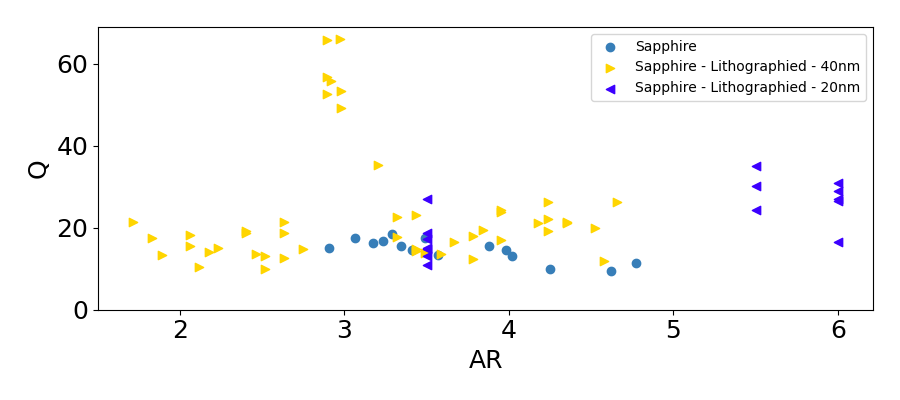

In [ ]:
if 0 :

    fig, ax = plt.subplots(figsize = (9,4))
    ax.set_xlabel('AR')
    ax.set_ylabel('Q')

    for key in ['Sapphire', 'Sapphire - Lithographied - 40nm', 'Sapphire - Lithographied - 20nm'] :
        print(key)
        exp_data = Exp_Data[key]
    
        
        idx = np.where(np.array([exp_data[kkey]['Q'] for kkey in exp_data]) != 0)[0]

        X = np.array([exp_data[kkey][AR_choice]['AR'] for kkey in exp_data])[idx]
        Y = np.array([exp_data[kkey]['Q'] for kkey in exp_data])[idx]


        
        plt.scatter(X, Y, color=Plot_dic[key]['main'], marker =Plot_dic[key]['marker'] , label = key)
        
    ax.set_ylim(bottom=0)
    plt.legend(fontsize=10)
    plt.tight_layout()

    os.chdir(dir_save_data)
    plt.savefig('All Sapphire Q factor - {} AR est.png'.format(AR_choice))
    plt.savefig('All Sapphire Q factor - {} AR est.pdf'.format(AR_choice))

## Plot Q(AR) for the 3 recent samples

In [7]:
if 0 :

    fig, ax = plt.subplots(figsize = (9,4))
    ax.set_xlabel('AR')
    ax.set_ylabel('Q')

    for key in ['Sapphire', 'Silice thick', 'Silice membrane'] :
        print(key)
        exp_data = Exp_Data[key]
    
        
        idx = np.where(np.array([exp_data[kkey]['Q'] for kkey in exp_data]) != 0)[0]

        X = np.array([exp_data[kkey][AR_choice]['AR'] for kkey in exp_data])[idx]
        Y = np.array([exp_data[kkey]['Q'] for kkey in exp_data])[idx]


        
        plt.scatter(X, Y, color=Plot_dic[key]['main'], marker =Plot_dic[key]['marker'] , label = key)
        
    ax.set_ylim(bottom=0)
    plt.legend(fontsize=10)
    plt.tight_layout()

    os.chdir(dir_save_data)
    plt.savefig('Q factor - 3 recent samples - {} AR est.png'.format(AR_choice))
    plt.savefig('Q factor - 3 recent samples - {} AR est.pdf'.format(AR_choice))


## Plot Q(AR) for Silica thick samples

In [8]:
if 0:
    fig, ax = plt.subplots(figsize = (9,4))
    ax.set_xlabel('AR')
    ax.set_ylabel('Q')

    for key in ['Silice thick', 'Silice thick - e 30 nm'] :
        print(key)
        exp_data = Exp_Data[key]
    
        
        idx = np.where(np.array([exp_data[kkey]['Q'] for kkey in exp_data]) != 0)[0]

        X = np.array([exp_data[kkey][AR_choice]['AR'] for kkey in exp_data])[idx]
        Y = np.array([exp_data[kkey]['Q'] for kkey in exp_data])[idx]


        # X2 = np.array([exp_data[kkey]['2D']['AR'] for kkey in exp_data])[idx]
        # Y2 = np.array([exp_data[kkey]['Q'] for kkey in exp_data])[idx]
        # plt.scatter(X2, Y2, color='black', marker =Plot_dic[key]['marker'] , label = '2D')
        
        
        plt.scatter(X, Y, color=Plot_dic[key]['main'], marker =Plot_dic[key]['marker'] , label = key)
        
    ax.set_ylim(bottom=0)
    plt.legend(fontsize=10)
    plt.tight_layout()
    os.chdir(dir_save_data)
    plt.savefig('Q factor Silice thick - 2 ND thichness - {} AR est.png'.format(AR_choice))
    plt.savefig('Q factor Silice thick - 2 ND thichness - {} AR est.pdf'.format(AR_choice))

In [9]:
if 0 :
        
    fig, ax = plt.subplots(figsize = (9,4))
    ax.set_xlabel('AR')
    ax.set_ylabel('T (ps)')

    for key in ['Silice thick', 'Silice thick - e 30 nm'] :
        print(key)
        print([exp_data[kkey][AR_choice]['AR'] for kkey in exp_data])
        exp_data = Exp_Data[key]
    
        
        idx = np.where(np.array([exp_data[kkey]['Q'] for kkey in exp_data]) != 0)[0]

        X = np.array([exp_data[kkey]['1D']['AR'] for kkey in exp_data])[idx]
        Y = np.array([exp_data[kkey]['T'] for kkey in exp_data])[idx]
        plt.scatter(X, Y, color=Plot_dic[key]['main'], marker =Plot_dic[key]['marker'] , label = key)



        idx = np.where(np.array([exp_data[kkey]['Q'] for kkey in exp_data]) != 0)[0]

        X2 = np.array([exp_data[kkey]['2D']['AR'] for kkey in exp_data])[idx]
        Y2 = np.array([exp_data[kkey]['T'] for kkey in exp_data])[idx]
        plt.scatter(X2, Y2, color='black', marker =Plot_dic[key]['marker'] , label = '2D')
        
        
    ax.set_ylim(bottom=0)
    plt.legend(fontsize=10)
    plt.tight_layout()



## Q(AR) for all samples

In [10]:
if 0 :
    fig, ax = plt.subplots(figsize = (9,6))
    ax.set_xlabel('AR')
    ax.set_ylabel('Q')



    for key in Exp_Data :
        print(key)
        exp_data = Exp_Data[key]
    
        
        plt.scatter([exp_data[kkey][AR_choice]['AR'] for kkey in exp_data], [exp_data[kkey]['Q'] for kkey in exp_data], color=Plot_dic[key]['main'],marker = Plot_dic[key]['marker'], label = key)

    plt.legend(fontsize=10)
    plt.tight_layout()

    os.chdir(dir_save_data)
    plt.savefig('Q factor - all samples - {} AR est.png'.format(AR_choice))
    plt.savefig('Q factor - all samples - {} AR est.pdf'.format(AR_choice))

Sapphire
Silice thick
Silice membrane
Sapphire - Lithographied - 40nm
Sapphire - Lithographied - 20nm


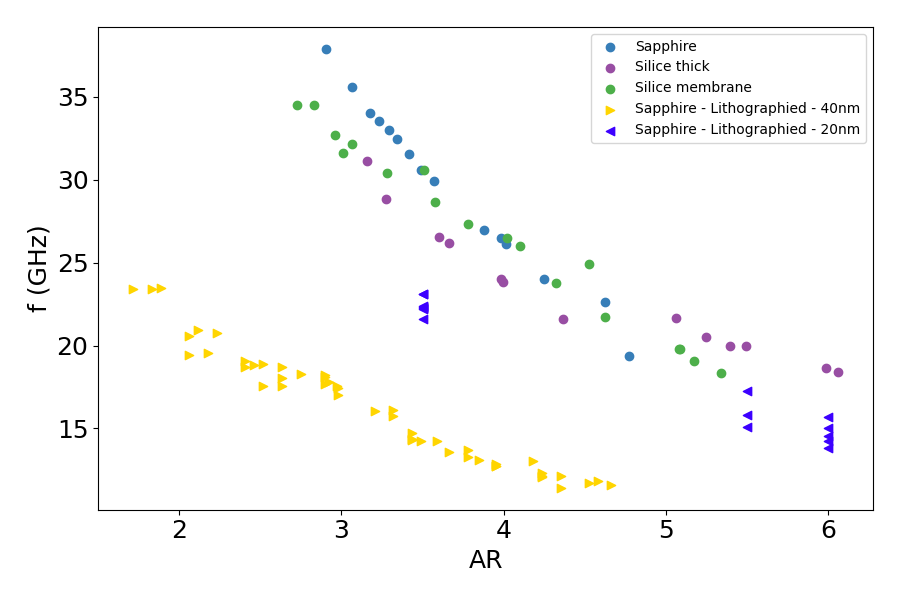

In [11]:
fig, ax = plt.subplots(figsize = (9,6))
ax.set_xlabel('AR')
ax.set_ylabel('f (GHz)')

for key in Exp_Data :
    print(key)
    exp_data = Exp_Data[key]
   

    idx = np.where(np.array([exp_data[kkey]['T'] for kkey in exp_data]) != 0)[0]

    X = np.array([exp_data[kkey][AR_choice]['AR'] for kkey in exp_data])[idx]
    Y = 1/np.array([(exp_data[kkey]['T']) for kkey in exp_data])[idx]*1e3

    plt.scatter(X, Y, color=Plot_dic[key]['main'],marker = Plot_dic[key]['marker'], label = key)

plt.legend(fontsize=10)
plt.tight_layout()


os.chdir(dir_save_data)
plt.savefig('f(AR) - all samples - {} AR est.png'.format(AR_choice))
plt.savefig('f(AR) - all samples - {} AR est.pdf'.format(AR_choice))


Sapphire
Silice thick
Silice membrane


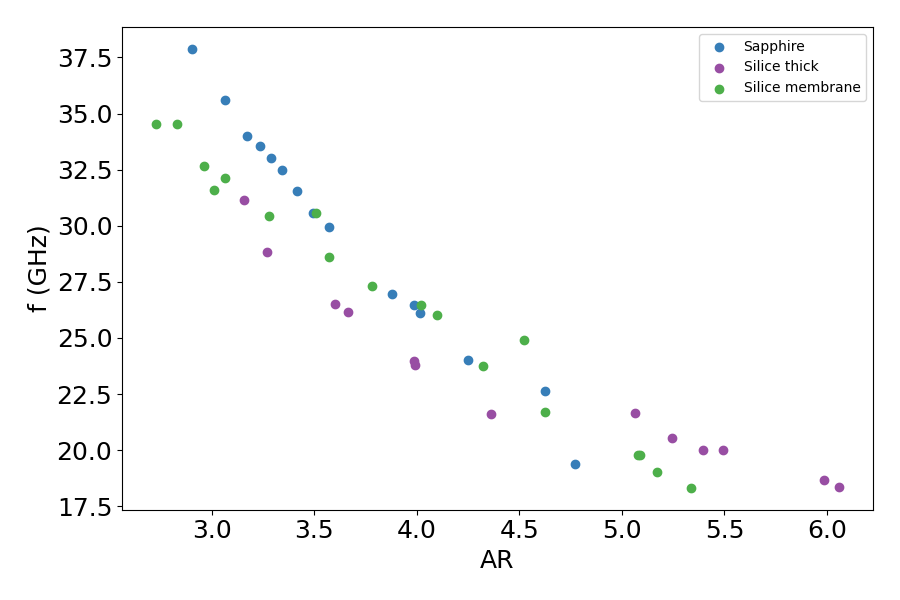

In [12]:
fig, ax = plt.subplots(figsize = (9,6))
ax.set_xlabel('AR')
ax.set_ylabel('f (GHz)')

for key in ['Sapphire', 'Silice thick', 'Silice membrane'] :
    print(key)
    exp_data = Exp_Data[key]
   

    idx = np.where(np.array([exp_data[kkey]['T'] for kkey in exp_data]) != 0)[0]

    X = np.array([exp_data[kkey][AR_choice]['AR'] for kkey in exp_data])[idx]
    Y = 1/np.array([(exp_data[kkey]['T']) for kkey in exp_data])[idx]*1e3

    plt.scatter(X, Y, color=Plot_dic[key]['main'],marker = Plot_dic[key]['marker'], label = key)

plt.legend(fontsize=10)
plt.tight_layout()


os.chdir(dir_save_data)
plt.savefig('f(AR) - my 3 samples - {} AR est.png'.format(AR_choice))
plt.savefig('f(AR) - my 3 samples - {} AR est.pdf'.format(AR_choice))

<>:3: SyntaxWarning: invalid escape sequence '\c'
<>:3: SyntaxWarning: invalid escape sequence '\c'
C:\Users\nberr\AppData\Local\Temp\ipykernel_16836\4054203187.py:3: SyntaxWarning: invalid escape sequence '\c'
  ax.set_ylabel('f_red (Hz $\cdot$ m)')


Sapphire
Silice thick
Silice membrane
Sapphire - Lithographied - 40nm
Sapphire - Lithographied - 20nm


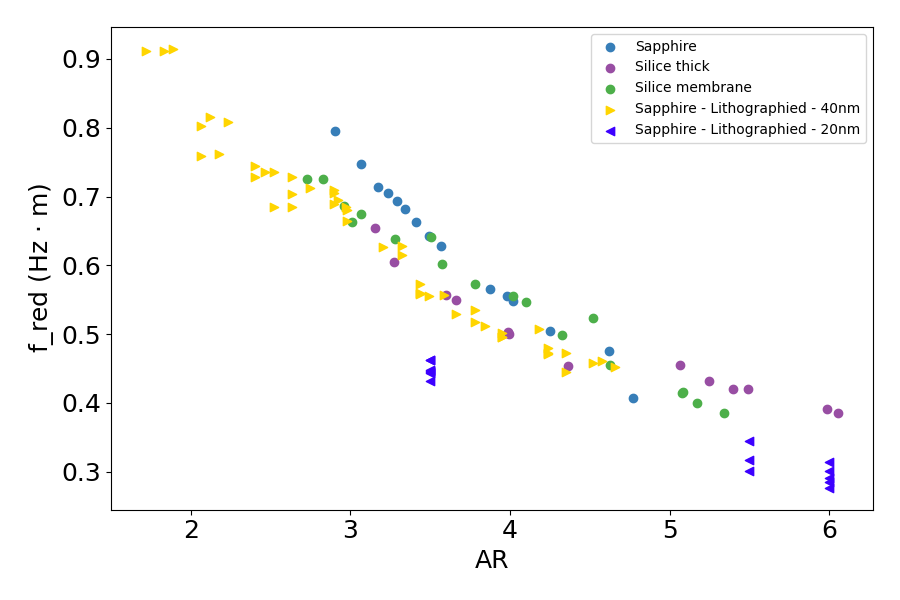

In [13]:
fig, ax = plt.subplots(figsize = (9,6))
ax.set_xlabel('AR')
ax.set_ylabel('f_red (Hz $\cdot$ m)')

for key in Exp_Data :
    print(key)
    exp_data = Exp_Data[key]


    idx = np.where(np.array([exp_data[kkey]['T'] for kkey in exp_data]) != 0)[0]

    X = np.array([exp_data[kkey][AR_choice]['AR'] for kkey in exp_data])[idx]
    Y = 1/np.array([(exp_data[kkey]['T']/exp_data[kkey][AR_choice]['h']) for kkey in exp_data])[idx]

    plt.scatter(X, Y, color=Plot_dic[key]['main'],marker = Plot_dic[key]['marker'], label = key)

plt.legend(fontsize=10)
plt.tight_layout()


os.chdir(dir_save_data)
plt.savefig('f_red(AR) - all samples - {} AR est.png'.format(AR_choice))
plt.savefig('f_red(AR) - all samples - {} AR est.pdf'.format(AR_choice))

## Compare periods with simulations

Sapphire
Silice thick
Silice membrane


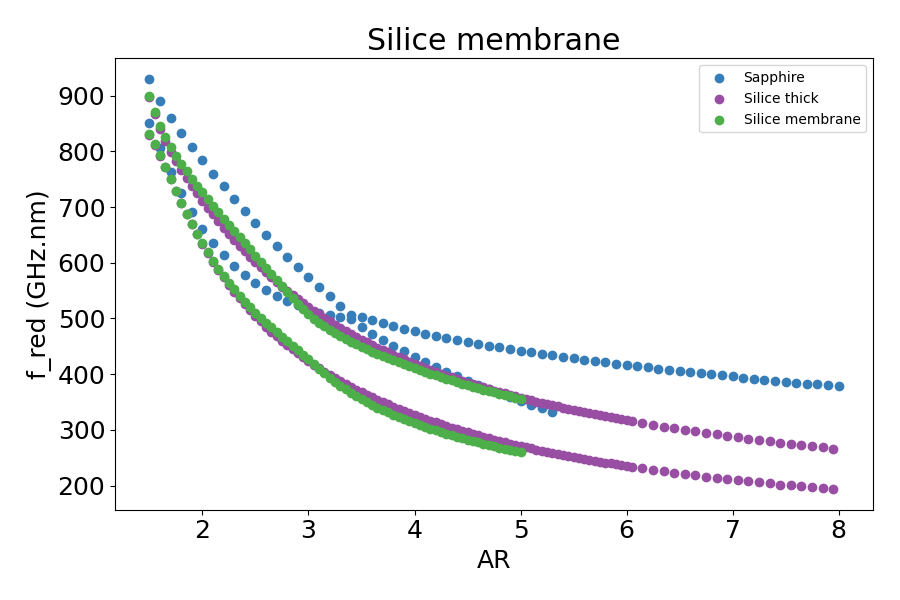

In [14]:
fig, ax = plt.subplots(figsize = (9,6))
ax.set_xlabel('AR')
ax.set_ylabel('f_red (GHz.nm)')
for key in Acoustic_simu_data :

    print(key)
    exp_data = Exp_Data[key]
   
    acoustic_data = Acoustic_simu_data[key][shape_choice]
    plt.scatter(acoustic_data['AR'], acoustic_data['freq']*20, color=Plot_dic[key]['main'],marker = Plot_dic[key]['marker'], label = key)
plt.title(key)
plt.legend(fontsize=10)
plt.tight_layout()

Sapphire
Silice thick
Silice membrane


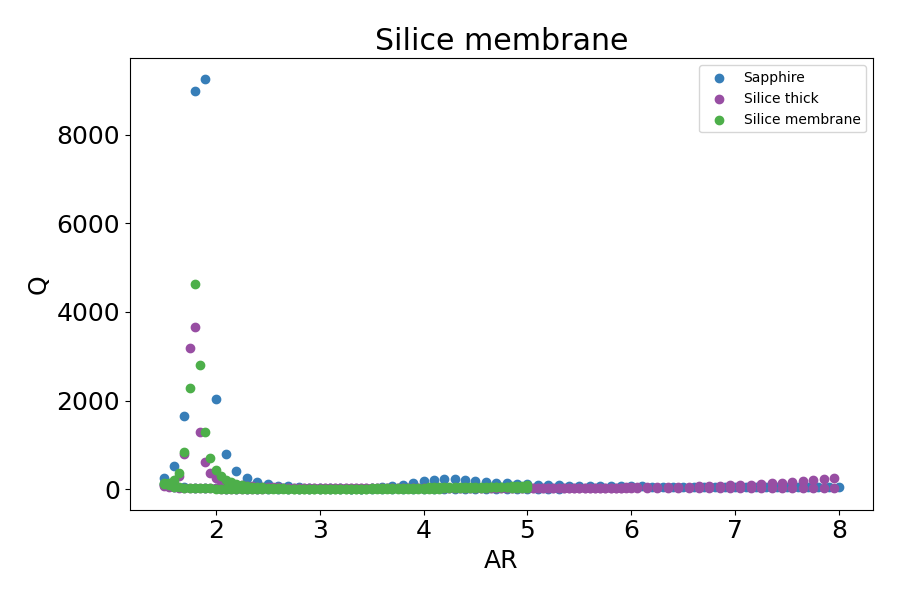

In [15]:

fig, ax = plt.subplots(figsize = (9,6))
ax.set_xlabel('AR')
ax.set_ylabel('Q')
for key in Acoustic_simu_data :

    print(key)
    exp_data = Exp_Data[key]
   
    acoustic_data = Acoustic_simu_data[key][shape_choice]
    plt.scatter(acoustic_data['AR'], acoustic_data['Q'], color=Plot_dic[key]['main'],marker = Plot_dic[key]['marker'], label = key)
plt.title(key)
plt.legend(fontsize=10)
plt.tight_layout()

Sapphire
[21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21]
Silice thick
[21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21]
Silice membrane
[21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21]


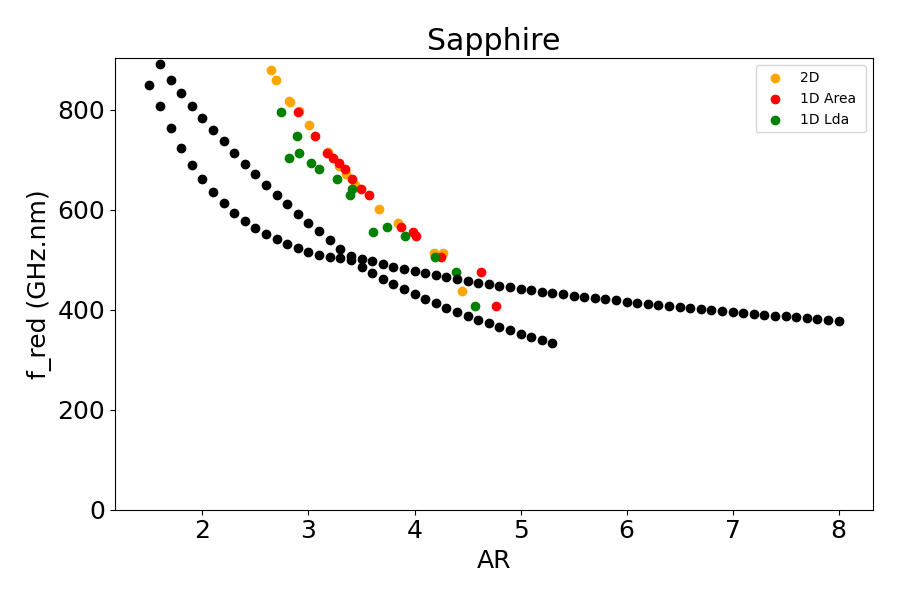

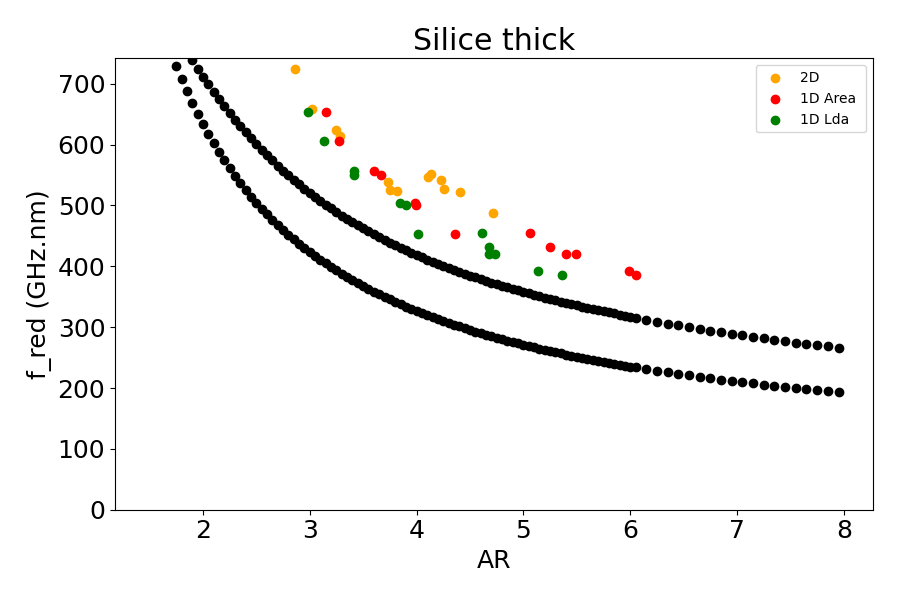

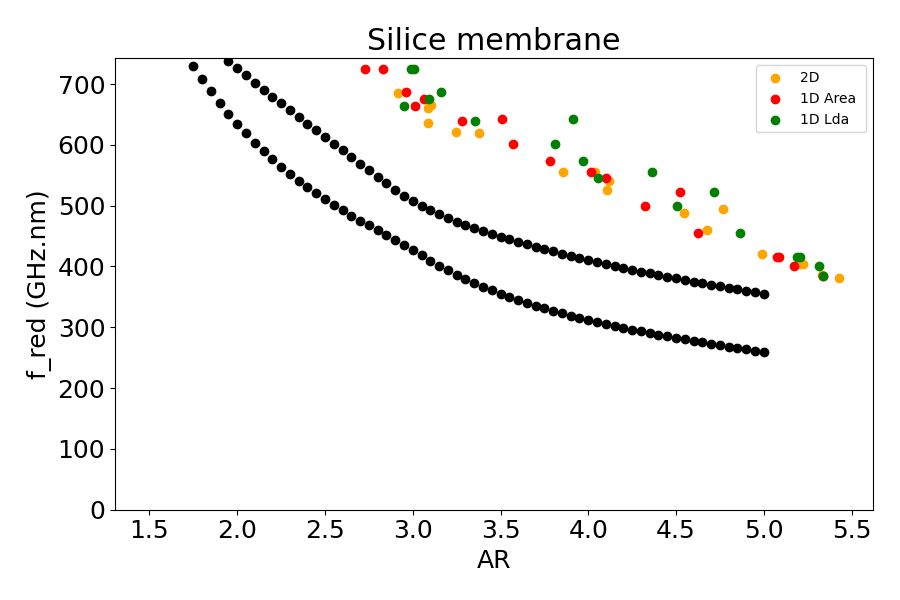

In [16]:
for key in Acoustic_simu_data :

    fig, ax = plt.subplots(figsize = (9,6))
    ax.set_xlabel('AR')
    ax.set_ylabel('f_red (GHz.nm)')
    print(key)
    exp_data = Exp_Data[key]
   
    acoustic_data = Acoustic_simu_data[key][shape_choice]

    idx = np.where(np.array([exp_data[kkey]['T'] for kkey in exp_data]) != 0)[0]

    # X = np.array([exp_data[kkey]['2D']['AR'] for kkey in exp_data])[idx]
    # Y = 1/np.array([(exp_data[kkey]['T'])/21 for kkey in exp_data])[idx]*1e3
    # plt.scatter(X, Y, color='orange',marker = Plot_dic[key]['marker'], label = '2D')

    # X = np.array([exp_data[kkey]['1D']['AR'] for kkey in exp_data])[idx]
    # Y = 1/np.array([(exp_data[kkey]['T'])/21 for kkey in exp_data])[idx]*1e3
    # plt.scatter(X, Y, color='red',marker = Plot_dic[key]['marker'], label = '1D Area ')


    # X = np.array([exp_data[kkey]['1D_Lda']['AR'] for kkey in exp_data])[idx]
    # Y = 1/np.array([(exp_data[kkey]['T'])/21 for kkey in exp_data])[idx]*1e3
    # plt.scatter(X, Y, color='green',marker = Plot_dic[key]['marker'], label = '1D Lda ')


    X = np.array([exp_data[kkey]['2D']['AR'] for kkey in exp_data])[idx]
    Y = 1/np.array([(exp_data[kkey]['T'])/exp_data[kkey]['2D']['h'] for kkey in exp_data])[idx]*1e3
    plt.scatter(X, Y, color='orange',marker = Plot_dic[key]['marker'], label = '2D')

    X = np.array([exp_data[kkey]['1D']['AR'] for kkey in exp_data])[idx]
    Y = 1/np.array([(exp_data[kkey]['T'])/exp_data[kkey]['1D']['h'] for kkey in exp_data])[idx]*1e3
    plt.scatter(X, Y, color='red',marker = Plot_dic[key]['marker'], label = '1D Area ')


    X = np.array([exp_data[kkey]['1D_Lda']['AR'] for kkey in exp_data])[idx]
    Y = 1/np.array([(exp_data[kkey]['T'])/exp_data[kkey]['1D_Lda']['h'] for kkey in exp_data])[idx]*1e3
    plt.scatter(X, Y, color='green',marker = Plot_dic[key]['marker'], label = '1D Lda ')

    print([exp_data[kkey]['1D']['h'] for kkey in exp_data])

    ax.set_ylim(bottom=0)
    plt.scatter(acoustic_data['AR'], acoustic_data['freq']*20, color='black')
    plt.title(key)
    plt.legend(fontsize=10)
    plt.tight_layout()

    
    os.chdir(dir_save_data)
    plt.savefig('f(AR) compar simul - {} - both AR est.png'.format(key, AR_choice))
    plt.savefig('f(AR) compar simul - {} - both AR est.pdf'.format(key, AR_choice))

    


## Compare Q factor with simulations

Sapphire
Silice thick
Silice membrane


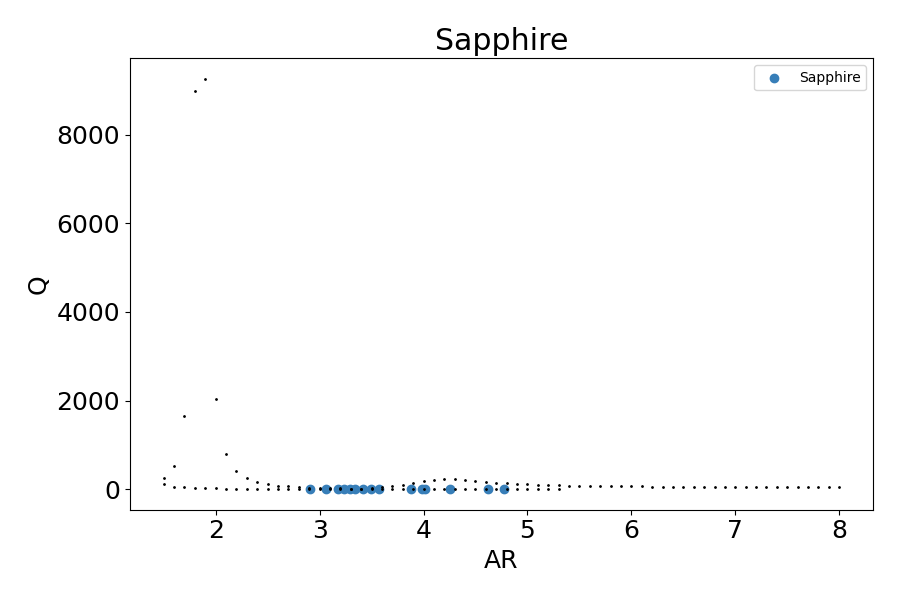

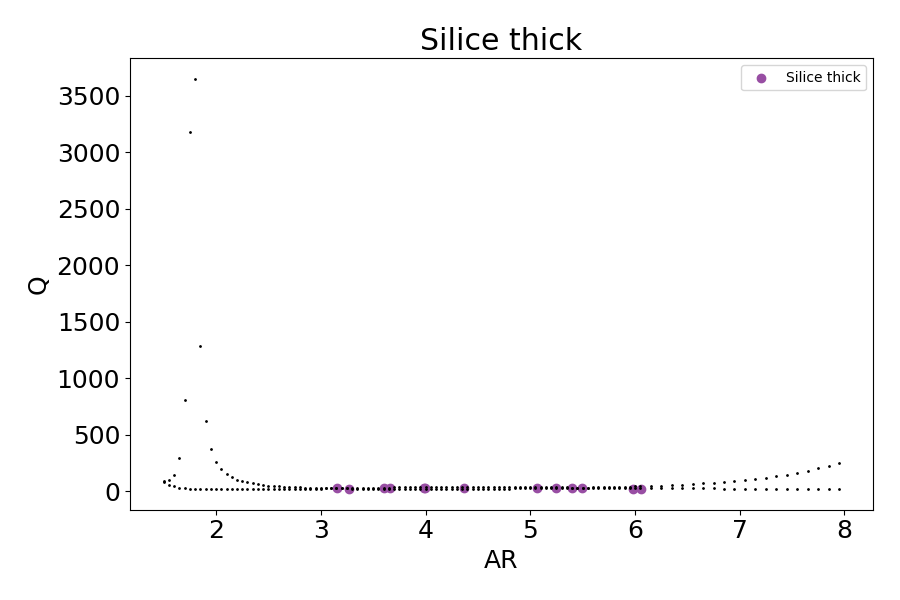

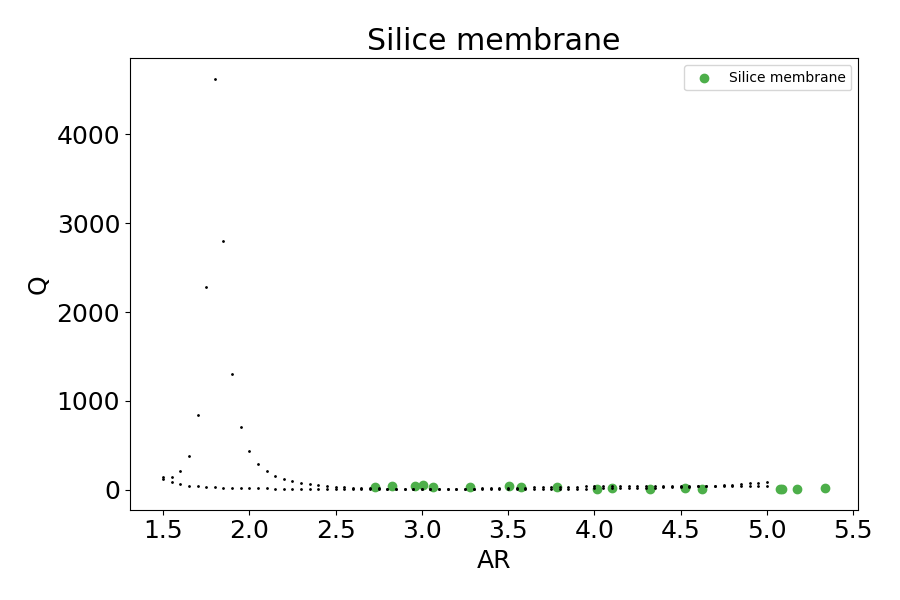

In [17]:
for key in Acoustic_simu_data :

    fig, ax = plt.subplots(figsize = (9,6))
    ax.set_xlabel('AR')
    ax.set_ylabel('Q')
    print(key)
    exp_data = Exp_Data[key]
   
    acoustic_data = Acoustic_simu_data[key][shape_choice]

    idx = np.where(np.array([exp_data[kkey]['T'] for kkey in exp_data]) != 0)[0]

    X = np.array([exp_data[kkey][AR_choice]['AR'] for kkey in exp_data])[idx]
    Y = np.array([(exp_data[kkey]['Q']) for kkey in exp_data])[idx]

    plt.scatter(X, Y, color=Plot_dic[key]['main'],marker = Plot_dic[key]['marker'], label = key)


    plt.scatter(acoustic_data['AR'], acoustic_data['Q'], color='black', s=1)
    plt.title(key)
    plt.legend(fontsize=10)
    plt.tight_layout()